# Logistic Regression: Breast Cancer (Malignant vs Benign)

This notebook trains a logistic regression classifier on the Wisconsin Diagnostic Breast Cancer (WDBC) dataset to predict whether a tumor is **malignant (M)** or **benign (B)** from 30 numeric features computed from digitized images of cell nuclei.

Authors: Logan Cooper, Mike Benko

In [1]:
# --- Imports ---
import pandas as pd                      # tabular data handling
import matplotlib.pyplot as plt          # plotting
import seaborn as sns                    # nicer statistical plots on top of matplotlib
from sklearn.model_selection import train_test_split   # split data into train/test sets
from sklearn.preprocessing import StandardScaler        # standardize features (mean 0, std 1)
from sklearn.linear_model import LogisticRegression     # the classifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report  # evaluation tools

# wdbc.data has no header row. Each of the 10 base measurements is reported three ways:
#   mean  = average over all nuclei in the image
#   se    = standard error of the measurement
#   worst = mean of the three largest values
base = ["radius", "texture", "perimeter", "area", "smoothness",
        "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"]
# Produces 30 names in file order: all *_mean, then all *_se, then all *_worst
names = [f"{b}_{s}" for s in ["mean", "se", "worst"] for b in base]

# --- Load the data ---
# Column 0 is a patient ID, column 1 is the diagnosis (M/B), then the 30 features
df = pd.read_csv("wdbc.data", header=None, names=["id", "diagnosis"] + names)
df.head()   # preview the first 5 rows

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Look at the data

Check the column types, confirm there are no missing values, and get summary statistics for each feature.

In [2]:
# Column names, data types, and non-null counts (569 rows, no missing values)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [3]:
# Summary statistics (mean, std, min, quartiles, max) for each numeric column.
# Note the very different scales: area is in the hundreds/thousands while
# smoothness is ~0.1 -- this is why we standardize the features later.
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


## Visualize

Compare class balance and how tumor size differs between the two diagnoses.

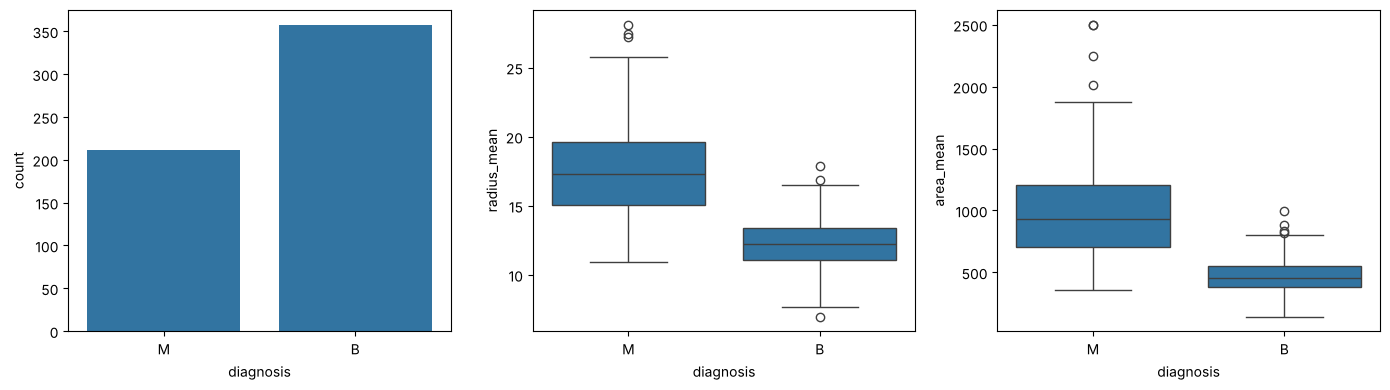

In [4]:
# Three side-by-side plots
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# 1) How many benign vs malignant samples (class balance)
sns.countplot(data=df, x="diagnosis", ax=axes[0])

# 2) Distribution of mean radius for each class
sns.boxplot(data=df, x="diagnosis", y="radius_mean", ax=axes[1])

# 3) Distribution of mean area for each class
sns.boxplot(data=df, x="diagnosis", y="area_mean", ax=axes[2])

plt.tight_layout()   # prevent labels from overlapping
plt.show()

**Observations:** Malignant tumors tend to be larger (higher radius and area). About 63% of tumors are benign, so "always guess benign" would already be ~63% accurate — that's the baseline our model needs to beat.

## Split, then scale

We split into training and test sets **before** scaling so the scaler only learns from training data. Fitting the scaler on the full dataset would leak information about the test set into training.

In [5]:
# --- Features and target ---
X = df.drop(columns=["id", "diagnosis"])   # 30 numeric features (ID is not a useful predictor)
y = (df["diagnosis"] == "M").astype(int)   # 1 = malignant, 0 = benign

# --- Train/test split ---
# 80% train / 20% test. random_state makes the split reproducible.
# stratify=y keeps the same benign/malignant ratio in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# --- Feature scaling ---
# Logistic regression (with its default L2 regularization) is sensitive to feature scale,
# so we transform every feature to mean 0 and standard deviation 1.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # learn mean/std from training data, then transform it
X_test = scaler.transform(X_test)         # apply the SAME training mean/std to the test data

## Train the model

Logistic regression computes a weighted sum of the features and passes it through the sigmoid function to get a probability of malignancy. Samples with probability ≥ 0.5 are predicted malignant.

In [6]:
# max_iter raised from the default (100) so the solver has enough iterations to converge
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)      # learn the feature weights from the training set
y_pred = model.predict(X_test)   # predict 0/1 labels for the unseen test set

# .score() returns accuracy = fraction of test samples classified correctly
print("Test accuracy:", round(model.score(X_test, y_test), 3))

Test accuracy: 0.965


## Evaluate

Accuracy alone can hide important errors. In a medical setting, a **false negative** (calling a malignant tumor benign) is far more costly than a false positive, so we look at the confusion matrix and per-class precision/recall.

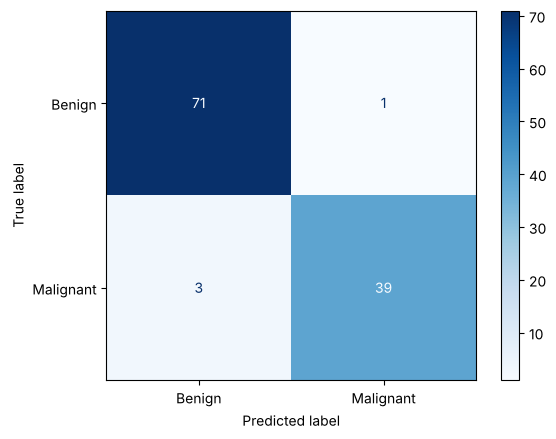

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [7]:
# Confusion matrix: rows = actual class, columns = predicted class
#   top-left: benign correctly predicted      top-right: benign predicted as malignant (false positive)
#   bottom-left: malignant predicted benign (false negative)   bottom-right: malignant correctly predicted
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Benign", "Malignant"]).plot(cmap="Blues")
plt.show()

# Per-class metrics:
#   precision = of the samples predicted as this class, how many were correct
#   recall    = of the samples actually in this class, how many were found
#   f1-score  = harmonic mean of precision and recall
#   support   = number of test samples in each class
print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))